# F3.5 — Entrenamiento final de los finalistas (val y prueba)

Figuras de apoyo de la tarea F3.5 (`docs/bitacora/F3.5.md`). Describen las 15 corridas de la fase `final`: tres finalistas de F3.3 con los hiperparámetros de F3.4 y cinco semillas (42, 7, 123, 2024 y 99), con la única consulta de prueba.

Reglas que sigue este notebook:

- **Toda cifra se lee de archivos versionados:** `results/f35_final/<técnica>/runs/*.json` y las predicciones F1.5 de `results/predictions/final/`.
- **Es descriptivo.** No compara contra BETO ni contra el techo 5D, y no emite veredicto. El contraste de no inferioridad (bootstrap pareado, Holm) le toca a SV en las Fases 4 y 5, con el procedimiento preregistrado.
- La predicción es `y_hat = 1` si y solo si `p_dep > 0.5` (F1.5 §3.3). La desviación estándar entre semillas usa `ddof=1`.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO = Path.cwd().resolve()
if not (REPO / 'src').is_dir():          # nbconvert ejecuta desde notebooks/
    REPO = REPO.parent
sys.path.insert(0, str(REPO / 'src'))
from viz import style

style.apply()
RES = REPO / 'results' / 'f35_final'
PRED = REPO / 'results' / 'predictions' / 'final'
FIG = RES / 'figures'
TECHS = ['gray_scott', 'perlin', 'lorenz']
FINALISTAS = {'gray_scott': ('efficientnet_b0', 'finetune'), 'perlin': ('vit_b16', 'frozen'),
              'lorenz': ('vit_b16', 'frozen')}
CFG_LABEL = {'gray_scott': 'EfficientNet-B0 fine-tuning', 'perlin': 'ViT-B/16 congelado',
             'lorenz': 'ViT-B/16 congelado'}
SEEDS = [42, 7, 123, 2024, 99]

def label(tech):
    return f'{style.TECH_LABEL[tech]} · {CFG_LABEL[tech]}'

def f1_macro(y, y_hat):
    f1 = []
    for k in (0, 1):
        tp = np.sum((y_hat == k) & (y == k)); fp = np.sum((y_hat == k) & (y != k)); fn = np.sum((y_hat != k) & (y == k))
        f1.append(2 * tp / (2 * tp + fp + fn))
    return float(np.mean(f1))

## Insumos

Se verifica que las tres carpetas son de la fase `final`, que hay cinco corridas por finalista con prueba, y que el F1-macro recalculado desde las predicciones F1.5 coincide con el registrado en cada JSON (val y prueba).

In [2]:
matriz = json.loads((REPO / 'configs' / 'matriz_experimentos.json').read_text(encoding='utf-8'))
MAX_EP = matriz['configuracion_comun']['max_epochs']
PATIENCE = matriz['configuracion_comun']['early_stopping']['patience']

runs = {}
for tech in TECHS:
    assert json.loads((RES / tech / 'grid_meta.json').read_text(encoding='utf-8')) == {'fase': 'final', 'smoke': False}
    rs = [json.loads(p.read_text(encoding='utf-8')) for p in sorted((RES / tech / 'runs').glob('*.json'))]
    assert sorted(r['seed'] for r in rs) == sorted(SEEDS)
    assert all(r['evaluate_test'] and (r['arch'], r['strategy']) == FINALISTAS[tech] for r in rs)
    runs[tech] = {r['seed']: r for r in rs}

PREDS = {}
for tech in TECHS:
    arch, strat = FINALISTAS[tech]
    for s in SEEDS:
        df = pd.read_csv(PRED / f'{tech}__{arch}__{strat}__seed{s}.csv', float_precision='round_trip')
        for split, key in (('val', 'best_f1_val'), ('test', 'f1_test')):
            d = df[df.split == split]
            assert len(d) == 114
            assert abs(f1_macro(d.y_true.to_numpy(), (d.p_dep > 0.5).astype(int).to_numpy()) - runs[tech][s][key]) < 1e-12
        PREDS[(tech, s)] = df

rows = []
for tech in TECHS:
    for s in SEEDS:
        r = runs[tech][s]
        rows.append(dict(technique=tech, seed=s, best_epoch=r['best_epoch'], epochs_run=r['epochs_run'],
                         por_tope=r['epochs_run'] == MAX_EP and r['best_epoch'] > MAX_EP - PATIENCE,
                         f1_val=r['best_f1_val'], f1_test=r['f1_test'], minutos=r['seconds'] / 60))
per_run = pd.DataFrame(rows)
resumen = per_run.groupby('technique', sort=False).agg(
    f1_val_media=('f1_val', 'mean'), f1_val_de=('f1_val', lambda x: x.std(ddof=1)),
    f1_test_media=('f1_test', 'mean'), f1_test_de=('f1_test', lambda x: x.std(ddof=1)),
    f1_test_min=('f1_test', 'min'), f1_test_max=('f1_test', 'max'),
    corridas_por_tope=('por_tope', 'sum'))
resumen['val_menos_test'] = resumen.f1_val_media - resumen.f1_test_media
print(f'{len(per_run)} corridas, F1 recalculado desde F1.5 = registrado (val y prueba)')
resumen.round(4)

15 corridas, F1 recalculado desde F1.5 = registrado (val y prueba)


,f1_val_media,f1_val_de,f1_test_media,f1_test_de,f1_test_min,f1_test_max,corridas_por_tope,val_menos_test
technique,,,,,,,,
gray_scott,0.7170,0.0093,0.7250,0.0180,0.6982,0.7449,1,-0.0080
perlin,0.7142,0.0168,0.6719,0.0151,0.6581,0.6902,0,0.0423
lorenz,0.7141,0.0035,0.7307,0.0146,0.7121,0.7449,0,-0.0167


## Figura 1. F1-val y F1-prueba por semilla

Un renglón por finalista. Cada semilla une su F1-val (punto hueco) con su F1-prueba (punto lleno). Las marcas verticales son las medias de val (hueca) y de prueba (llena). Una línea que va a la izquierda indica que la semilla rinde menos en prueba que en validación, el conjunto con el que se eligieron la configuración y los hiperparámetros. Con 114 muestras el F1-macro toma pocos valores, así que varias semillas pueden coincidir.

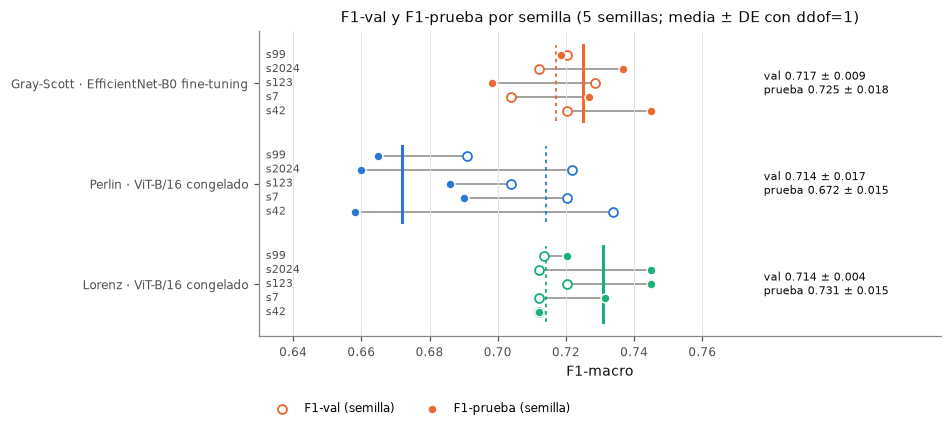

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.6))
OFFS = dict(zip(SEEDS, np.linspace(-0.28, 0.28, len(SEEDS))))
for i, tech in enumerate(TECHS):
    color = style.TECH_COLOR[tech]
    y0 = len(TECHS) - 1 - i
    for s in SEEDS:
        r = runs[tech][s]; y = y0 + OFFS[s]
        ax.plot([r['best_f1_val'], r['f1_test']], [y, y], color=style.MUTED, lw=1, zorder=1)
        ax.scatter(r['best_f1_val'], y, s=34, facecolors='white', edgecolors=color, linewidths=1.2, zorder=3,
                   label='F1-val (semilla)' if (i == 0 and s == SEEDS[0]) else None)
        ax.scatter(r['f1_test'], y, s=34, color=color, edgecolors=style.SURFACE, linewidths=1, zorder=3,
                   label='F1-prueba (semilla)' if (i == 0 and s == SEEDS[0]) else None)
        ax.text(0.632, y, f's{s}', va='center', ha='left', fontsize=style.FONT_SIZES['annot'], color=style.INK_SECONDARY)
    m = resumen.loc[tech]
    ax.plot([m.f1_val_media] * 2, [y0 - 0.38, y0 + 0.38], color=color, lw=1.2, ls=(0, (2, 2)))
    ax.plot([m.f1_test_media] * 2, [y0 - 0.38, y0 + 0.38], color=color, lw=2)
    ax.text(0.778, y0, f'val {m.f1_val_media:.3f} ± {m.f1_val_de:.3f}\nprueba {m.f1_test_media:.3f} ± {m.f1_test_de:.3f}',
            va='center', fontsize=style.FONT_SIZES['annot'], color=style.INK)
ax.set_yticks(range(len(TECHS)))
ax.set_yticklabels([label(t) for t in reversed(TECHS)])
ax.set_xlim(0.63, 0.83)
ax.set_xticks(np.arange(0.64, 0.77, 0.02))
ax.set_xlabel('F1-macro')
ax.grid(axis='x')
ax.set_title('F1-val y F1-prueba por semilla (5 semillas; media ± DE con ddof=1)')
ax.legend(loc='upper left', bbox_to_anchor=(0, -0.18), ncol=2)
style.save(fig, FIG / 'f1_val_vs_prueba')
plt.show()

## Figura 2. Curvas de aprendizaje

Arriba, F1-val por época; abajo, pérdida de entrenamiento (entropía cruzada con pesos de clase). Una columna por finalista y una línea por semilla (`history` de cada JSON). El punto marca la mejor época por F1-val, que es el modelo guardado y evaluado en prueba. La línea termina donde actuó la parada temprana (paciencia 4) o el tope de 15 épocas; la banda sombreada marca las épocas en las que una mejor época implicaría que la corrida la detuvo el tope (✕).

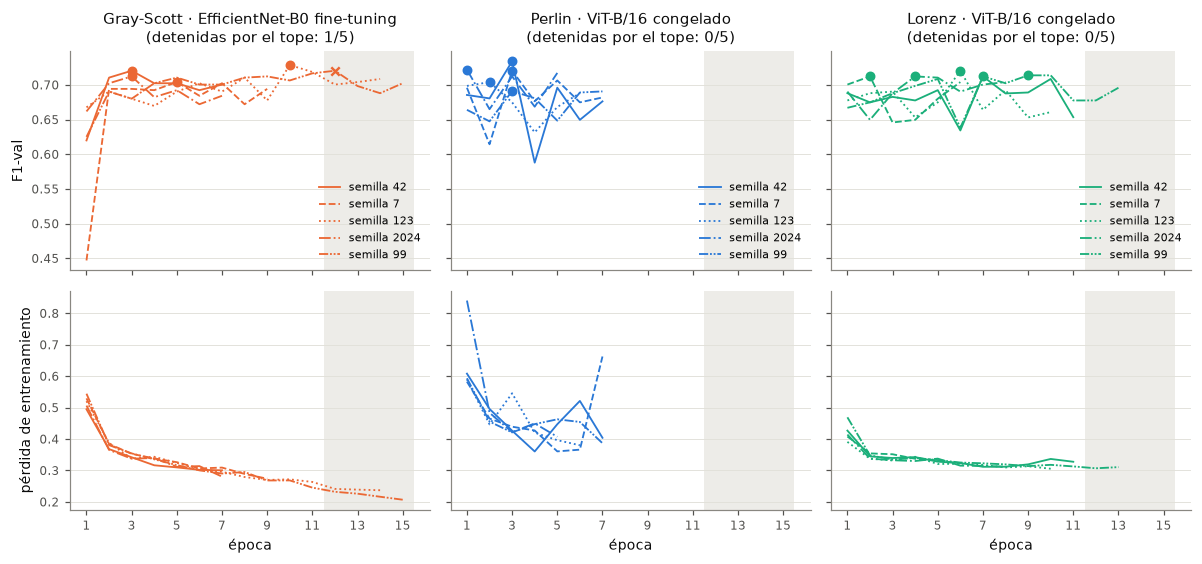

In [4]:
SEED_STYLE = {42: '-', 7: '--', 123: ':', 2024: '-.', 99: (0, (5, 1, 1, 1, 1, 1))}
fig, axes = plt.subplots(2, 3, figsize=(11, 5.2), sharex=True, sharey='row')
for j, tech in enumerate(TECHS):
    color = style.TECH_COLOR[tech]
    for s in SEEDS:
        r = runs[tech][s]
        ep = np.arange(1, r['epochs_run'] + 1)
        for i, key in enumerate(('f1_val', 'train_loss')):
            ax = axes[i, j]
            ax.plot(ep, r['history'][key], ls=SEED_STYLE[s], color=color, lw=1.2, label=f'semilla {s}' if i == 0 else None)
            if key == 'f1_val':
                tope = r['epochs_run'] == MAX_EP and r['best_epoch'] > MAX_EP - PATIENCE
                ax.scatter(r['best_epoch'], r['best_f1_val'], marker='x' if tope else 'o', s=30, color=color, zorder=3)
    for i in range(2):
        axes[i, j].axvspan(MAX_EP - PATIENCE + 0.5, MAX_EP + 0.5, color=style.GRID, alpha=0.6, lw=0)
        axes[i, j].grid(axis='y')
    n_tope = int(resumen.loc[tech, 'corridas_por_tope'])
    axes[0, j].set_title(f'{label(tech)}\n(detenidas por el tope: {n_tope}/5)')
    axes[1, j].set_xlabel('época')
    axes[0, j].legend(loc='lower right', fontsize=style.FONT_SIZES['annot'])
axes[0, 0].set_ylabel('F1-val')
axes[1, 0].set_ylabel('pérdida de entrenamiento')
axes[1, 0].set_xticks(range(1, MAX_EP + 1, 2))
fig.tight_layout()
style.save(fig, FIG / 'curvas_aprendizaje')
plt.show()

## Figura 3. Distribución de `p_dep` en prueba y matriz de confusión

Una fila por finalista. **Izquierda:** histograma de `p_dep` en prueba por clase real, con las cinco semillas juntas (5 × 114 = 570 predicciones). La línea discontinua es el umbral 0.5. **Derecha:** matriz de confusión de prueba, con el conteo medio de las cinco semillas y el tono como proporción por fila (clase real). El título indica la tasa media de falsos negativos (depresivos clasificados como no depresivos).

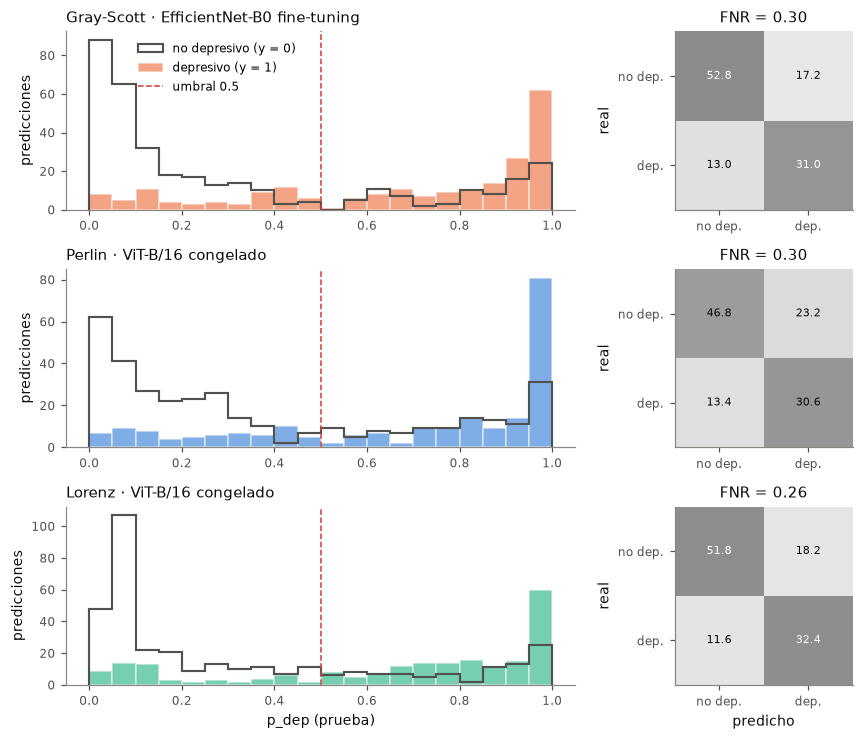

In [5]:
bins = np.linspace(0, 1, 21)
fig, axes = plt.subplots(len(TECHS), 2, figsize=(8, 2.0 * len(TECHS) + 0.8), gridspec_kw={'width_ratios': [3, 1.15]})
for i, tech in enumerate(TECHS):
    color = style.TECH_COLOR[tech]
    T = [PREDS[(tech, s)].query("split == 'test'") for s in SEEDS]
    y = T[0].y_true.to_numpy()
    assert all((t.y_true.to_numpy() == y).all() for t in T)
    P = np.column_stack([t.p_dep.to_numpy() for t in T])
    Y_hat = (P > 0.5).astype(int)
    ax = axes[i, 0]
    ax.hist(P[y == 0].ravel(), bins=bins, histtype='step', color=style.INK_SECONDARY, lw=1.4, label='no depresivo (y = 0)')
    ax.hist(P[y == 1].ravel(), bins=bins, color=color, alpha=0.6, edgecolor=style.SURFACE, lw=1, label='depresivo (y = 1)')
    ax.axvline(0.5, color=style.THRESHOLD_COLOR, lw=1, ls='--', label='umbral 0.5')
    ax.set_ylabel('predicciones')
    ax.set_title(label(tech), loc='left')
    if i == 0:
        ax.legend(loc='upper left', bbox_to_anchor=(0.12, 1))
    if i == len(TECHS) - 1:
        ax.set_xlabel('p_dep (prueba)')
    cm = np.zeros((2, 2))
    for k in range(len(SEEDS)):
        for a in (0, 1):
            for b in (0, 1):
                cm[a, b] += np.sum((y == a) & (Y_hat[:, k] == b))
    cm /= len(SEEDS)
    prop = cm / cm.sum(axis=1, keepdims=True)
    ax = axes[i, 1]
    ax.imshow(prop, cmap='Greys', vmin=0, vmax=1.4)
    for a in (0, 1):
        for b in (0, 1):
            ax.text(b, a, f'{cm[a, b]:.1f}', ha='center', va='center', fontsize=style.FONT_SIZES['annot'],
                    color='white' if prop[a, b] > 0.7 else style.INK)
    ax.set_xticks([0, 1]); ax.set_xticklabels(['no dep.', 'dep.'])
    ax.set_yticks([0, 1]); ax.set_yticklabels(['no dep.', 'dep.'])
    ax.set_ylabel('real'); ax.set_xlabel('predicho' if i == len(TECHS) - 1 else '')
    ax.set_title(f'FNR = {cm[1, 0] / cm[1].sum():.2f}')
fig.tight_layout()
style.save(fig, FIG / 'predicciones_prueba')
plt.show()

## Figura 4. Acuerdo entre semillas en prueba

Para cada finalista y cada muestra de prueba se cuenta en cuántas de las cinco semillas la predicción es correcta. La barra reparte las 114 muestras de 5/5 a 0/5 aciertos. Las muestras con 5/5 o 0/5 son **unánimes**; su proporción se anota a la derecha. Si el acuerdo es bajo, la semilla decide buena parte de las predicciones, y eso pesa en las pruebas pareadas de las Fases 4 y 5. Las muestras con 0/5 son errores sistemáticos.

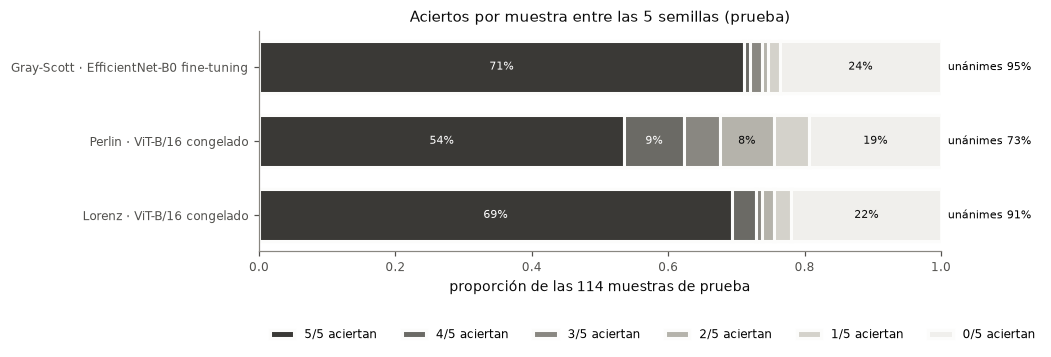

,5/5,4/5,3/5,2/5,1/5,0/5,unanimes
technique,,,,,,,
gray_scott,0.711,0.009,0.018,0.009,0.018,0.237,0.947
perlin,0.535,0.088,0.053,0.079,0.053,0.193,0.728
lorenz,0.693,0.035,0.009,0.018,0.026,0.219,0.912


In [6]:
RAMP = {0: '#f0efec', 1: '#d4d2cb', 2: '#b5b3ab', 3: '#898781', 4: '#6b6a65', 5: '#3a3936'}
TEXT_ON = {0: style.INK, 1: style.INK, 2: style.INK, 3: 'white', 4: 'white', 5: 'white'}
fig, ax = plt.subplots(figsize=(8, 2.6))
acuerdo = []
for i, tech in enumerate(TECHS):
    T = [PREDS[(tech, s)].query("split == 'test'") for s in SEEDS]
    y = T[0].y_true.to_numpy()
    k = np.column_stack([(t.p_dep.to_numpy() > 0.5).astype(int) == y for t in T]).sum(axis=1)
    frac = {n: float(np.mean(k == n)) for n in range(5, -1, -1)}
    acuerdo.append(dict(technique=tech, **{f'{n}/5': frac[n] for n in frac}, unanimes=frac[5] + frac[0]))
    left = 0.0
    yi = len(TECHS) - 1 - i
    for n, f in frac.items():
        ax.barh(yi, f, left=left, color=RAMP[n], edgecolor=style.SURFACE, lw=2, height=0.7,
                label=f'{n}/5 aciertan' if i == 0 else None)
        if f >= 0.06:
            ax.text(left + f / 2, yi, f'{f:.0%}', ha='center', va='center', fontsize=style.FONT_SIZES['annot'], color=TEXT_ON[n])
        left += f
    ax.text(1.01, yi, f'unánimes {frac[5] + frac[0]:.0%}', va='center', fontsize=style.FONT_SIZES['annot'])
ax.set_yticks(range(len(TECHS)))
ax.set_yticklabels([label(t) for t in reversed(TECHS)])
ax.set_xlim(0, 1)
ax.set_xlabel('proporción de las 114 muestras de prueba')
ax.legend(loc='upper left', bbox_to_anchor=(0, -0.3), ncol=6)
ax.set_title('Aciertos por muestra entre las 5 semillas (prueba)')
style.save(fig, FIG / 'acuerdo_semillas_prueba')
plt.show()
pd.DataFrame(acuerdo).set_index('technique').round(3)